<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab2_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Cell 2: Download Heart Failure Clinical Records Dataset

import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00519/heart_failure_clinical_records_dataset.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

Dataset downloaded successfully!
Dataset shape: (299, 13)


In [5]:
# Cell 3: Display first 5 rows

df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [6]:
# Cell 4: Rows, columns, data types and missing values

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Number of rows: 299
Number of columns: 13

Data Types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Missing Values:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


In [7]:
# Cell 5: Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


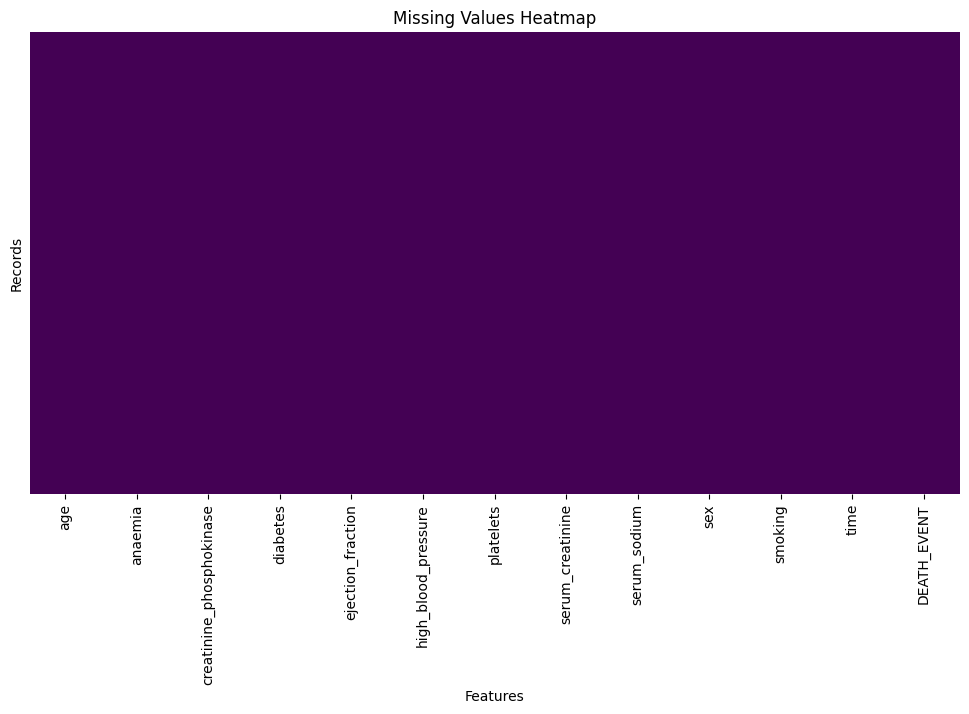

In [8]:
# Cell 6: Visualize missing values

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.xlabel("Features")
plt.ylabel("Records")
plt.show()

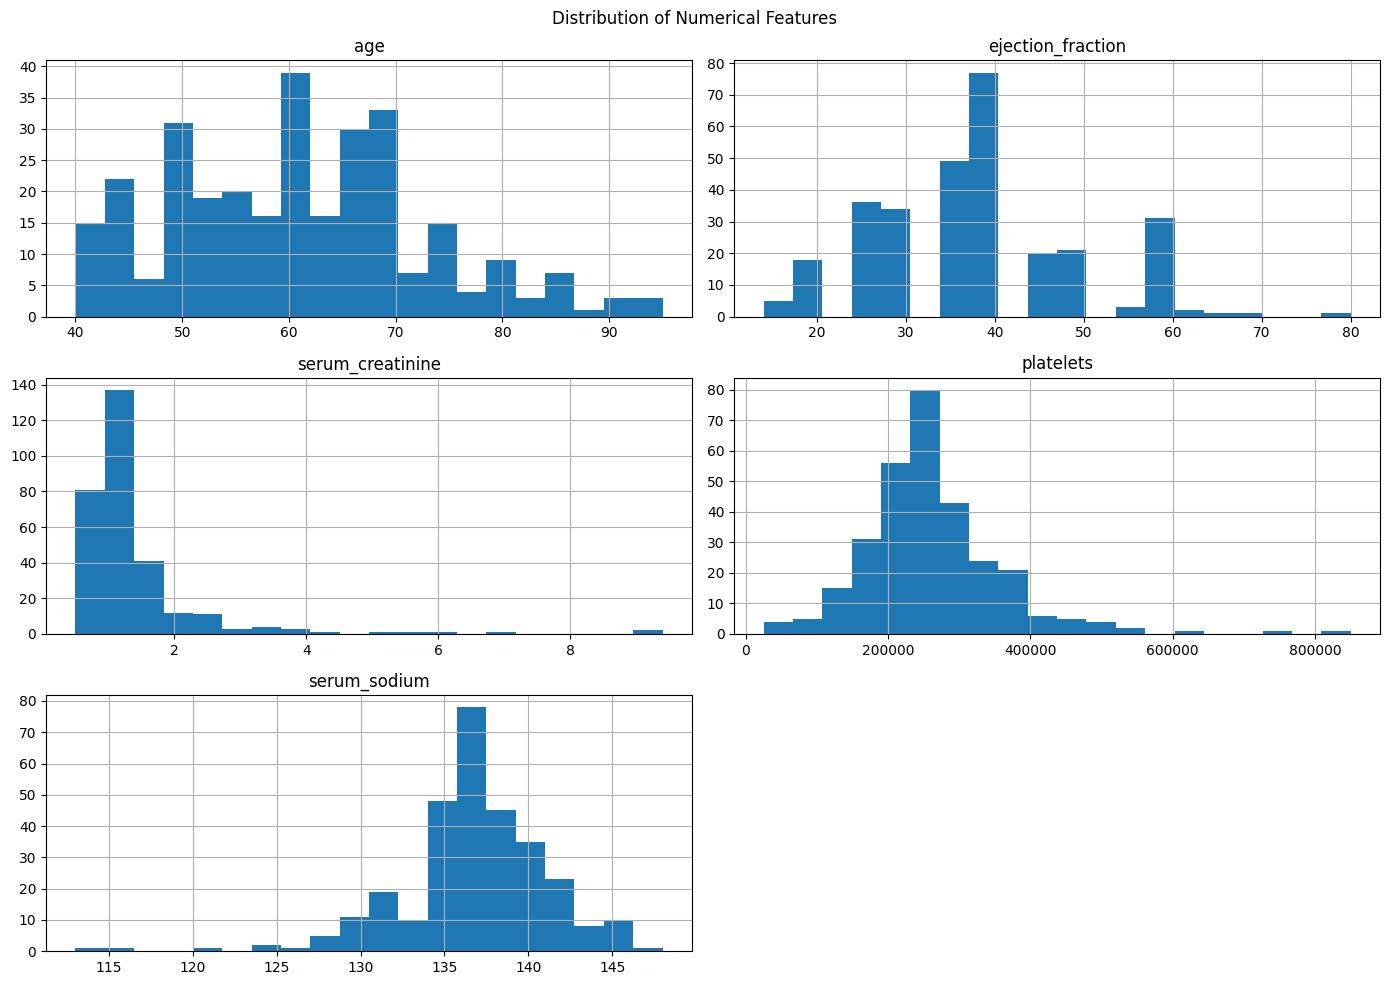

In [9]:
# Cell 7: Histograms of numerical features

numerical_columns = [
    "age",
    "ejection_fraction",
    "serum_creatinine",
    "platelets",
    "serum_sodium"
]

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

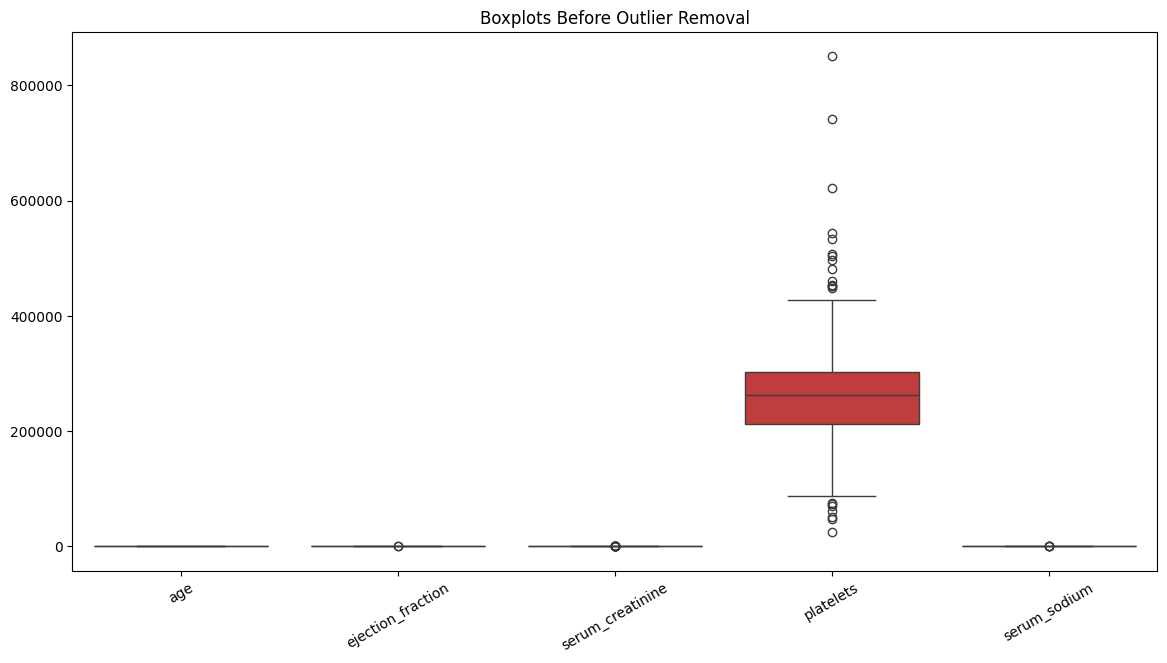

In [10]:
# Cell 8: Boxplots to identify outliers

plt.figure(figsize=(14, 7))

sns.boxplot(data=df[numerical_columns])

plt.title("Boxplots Before Outlier Removal")
plt.xticks(rotation=30)
plt.show()

In [11]:
# Cell 9: Summary statistics before cleaning

before_cleaning = df[numerical_columns].agg(
    ["mean", "median", "std"]
).T

before_cleaning

,mean,median,std
age,60.833893,60.0,11.894809
ejection_fraction,38.083612,38.0,11.834841
serum_creatinine,1.393880,1.1,1.034510
platelets,263358.029264,262000.0,97804.236869
serum_sodium,136.625418,137.0,4.412477


In [12]:
# Cell 10: Check for invalid values

print("Negative ages:")
print(df[df["age"] < 0])

print("\nInvalid ejection fraction:")
print(df[df["ejection_fraction"] <= 0])

print("\nInvalid serum creatinine:")
print(df[df["serum_creatinine"] <= 0])

print("\nInvalid serum sodium:")
print(df[df["serum_sodium"] <= 0])

Negative ages:
Empty DataFrame
Columns: [age, anaemia, creatinine_phosphokinase, diabetes, ejection_fraction, high_blood_pressure, platelets, serum_creatinine, serum_sodium, sex, smoking, time, DEATH_EVENT]
Index: []

Invalid ejection fraction:
Empty DataFrame
Columns: [age, anaemia, creatinine_phosphokinase, diabetes, ejection_fraction, high_blood_pressure, platelets, serum_creatinine, serum_sodium, sex, smoking, time, DEATH_EVENT]
Index: []

Invalid serum creatinine:
Empty DataFrame
Columns: [age, anaemia, creatinine_phosphokinase, diabetes, ejection_fraction, high_blood_pressure, platelets, serum_creatinine, serum_sodium, sex, smoking, time, DEATH_EVENT]
Index: []

Invalid serum sodium:
Empty DataFrame
Columns: [age, anaemia, creatinine_phosphokinase, diabetes, ejection_fraction, high_blood_pressure, platelets, serum_creatinine, serum_sodium, sex, smoking, time, DEATH_EVENT]
Index: []


In [13]:
# Cell 11: Correct invalid values

# Replace invalid ages with NaN
df.loc[df["age"] < 0, "age"] = np.nan

# Replace invalid numerical values with NaN
df.loc[df["ejection_fraction"] <= 0, "ejection_fraction"] = np.nan
df.loc[df["serum_creatinine"] <= 0, "serum_creatinine"] = np.nan
df.loc[df["serum_sodium"] <= 0, "serum_sodium"] = np.nan

print("Invalid values converted to NaN.")

Invalid values converted to NaN.


In [14]:
# Cell 12: Optional - create missing values for demonstration

# Uncomment if your dataset has no missing values
# np.random.seed(42)
# df.loc[np.random.choice(df.index, 5), "serum_creatinine"] = np.nan
# df.loc[np.random.choice(df.index, 5), "smoking"] = np.nan

print("Current missing values:")
print(df.isnull().sum())

Current missing values:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


In [15]:
# Cell 13: Impute numerical missing values using median

numerical_columns = [
    "age",
    "ejection_fraction",
    "serum_creatinine",
    "platelets",
    "serum_sodium"
]

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

print("Numerical missing values imputed.")

Numerical missing values imputed.


In [16]:
# Cell 14: Impute categorical missing values using mode

categorical_columns = ["sex", "smoking"]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Categorical missing values imputed.")

Categorical missing values imputed.


In [17]:
# Cell 15: Remove outliers using IQR method

def remove_outliers_iqr(data, columns):
    cleaned_data = data.copy()

    for col in columns:
        Q1 = cleaned_data[col].quantile(0.25)
        Q3 = cleaned_data[col].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        cleaned_data = cleaned_data[
            (cleaned_data[col] >= lower_bound) &
            (cleaned_data[col] <= upper_bound)
        ]

    return cleaned_data


rows_before = len(df)

df = remove_outliers_iqr(df, numerical_columns)

rows_after = len(df)

print("Rows before outlier removal:", rows_before)
print("Rows after outlier removal:", rows_after)
print("Outliers removed:", rows_before - rows_after)

Rows before outlier removal: 299
Rows after outlier removal: 244
Outliers removed: 55


In [18]:
# Cell 16: Create age_group feature

def age_group(age):
    if age < 40:
        return "<40"
    elif age <= 60:
        return "40-60"
    else:
        return ">60"

df["age_group"] = df["age"].apply(age_group)

df[["age", "age_group"]].head(10)

,age,age_group
0,75.0,>60
1,55.0,40-60
2,65.0,>60
3,50.0,40-60
5,90.0,>60
6,75.0,>60
8,65.0,>60
11,62.0,>60
12,45.0,40-60
13,50.0,40-60


In [19]:
# Cell 17: Create risk_score

# Normalize the two components first
ef_norm = (
    (df["ejection_fraction"] - df["ejection_fraction"].min()) /
    (df["ejection_fraction"].max() - df["ejection_fraction"].min())
)

creatinine_norm = (
    (df["serum_creatinine"] - df["serum_creatinine"].min()) /
    (df["serum_creatinine"].max() - df["serum_creatinine"].min())
)

# Product of normalized features
df["risk_score"] = ef_norm * creatinine_norm

df[["ejection_fraction", "serum_creatinine", "risk_score"]].head()

,ejection_fraction,serum_creatinine,risk_score
0,20.0,1.9,0.0875
1,38.0,1.1,0.1725
2,20.0,1.3,0.0500
3,20.0,1.9,0.0875
5,40.0,2.1,0.5000


In [20]:
# Cell 18: One-hot encoding

df_encoded = pd.get_dummies(
    df,
    columns=["sex", "smoking", "age_group"],
    drop_first=True
)

print("Dataset after encoding:")
df_encoded.head()

Dataset after encoding:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT,risk_score,sex_1,smoking_1,age_group_>60
0,75.0,0,582,0,20.0,1,265000.00,1.9,130.0,4,1,0.0875,True,False,True
1,55.0,0,7861,0,38.0,0,263358.03,1.1,136.0,6,1,0.1725,True,False,False
2,65.0,0,146,0,20.0,0,162000.00,1.3,129.0,7,1,0.0500,True,True,True
3,50.0,1,111,0,20.0,0,210000.00,1.9,137.0,7,1,0.0875,True,False,False
5,90.0,1,47,0,40.0,1,204000.00,2.1,132.0,8,1,0.5000,True,True,True


In [21]:
# Cell 19: Normalize numerical features using MinMaxScaler

scaler = MinMaxScaler()

df_encoded[numerical_columns] = scaler.fit_transform(
    df_encoded[numerical_columns]
)

print("Numerical features normalized to 0-1.")
df_encoded[numerical_columns].head()

Numerical features normalized to 0-1.


,age,ejection_fraction,serum_creatinine,platelets,serum_sodium
0,0.636364,0.10,0.875,0.496894,0.117647
1,0.272727,0.46,0.375,0.491795,0.470588
2,0.454545,0.10,0.500,0.177019,0.058824
3,0.181818,0.10,0.875,0.326087,0.529412
5,0.909091,0.50,1.000,0.307453,0.235294


In [22]:
# Cell 20: Summary statistics after cleaning

after_cleaning = df_encoded[numerical_columns].agg(
    ["mean", "median", "std"]
).T

after_cleaning

,mean,median,std
age,0.370219,0.363636,0.216234
ejection_fraction,0.458197,0.460000,0.227167
serum_creatinine,0.387705,0.312500,0.203714
platelets,0.469859,0.489130,0.210350
serum_sodium,0.541948,0.529412,0.204500


In [23]:
# Cell 21: Compare statistics

comparison = pd.concat(
    [
        before_cleaning.add_suffix("_before"),
        after_cleaning.add_suffix("_after")
    ],
    axis=1
)

comparison

,mean_before,median_before,std_before,mean_after,median_after,std_after
age,60.833893,60.0,11.894809,0.370219,0.363636,0.216234
ejection_fraction,38.083612,38.0,11.834841,0.458197,0.460000,0.227167
serum_creatinine,1.393880,1.1,1.034510,0.387705,0.312500,0.203714
platelets,263358.029264,262000.0,97804.236869,0.469859,0.489130,0.210350
serum_sodium,136.625418,137.0,4.412477,0.541948,0.529412,0.204500


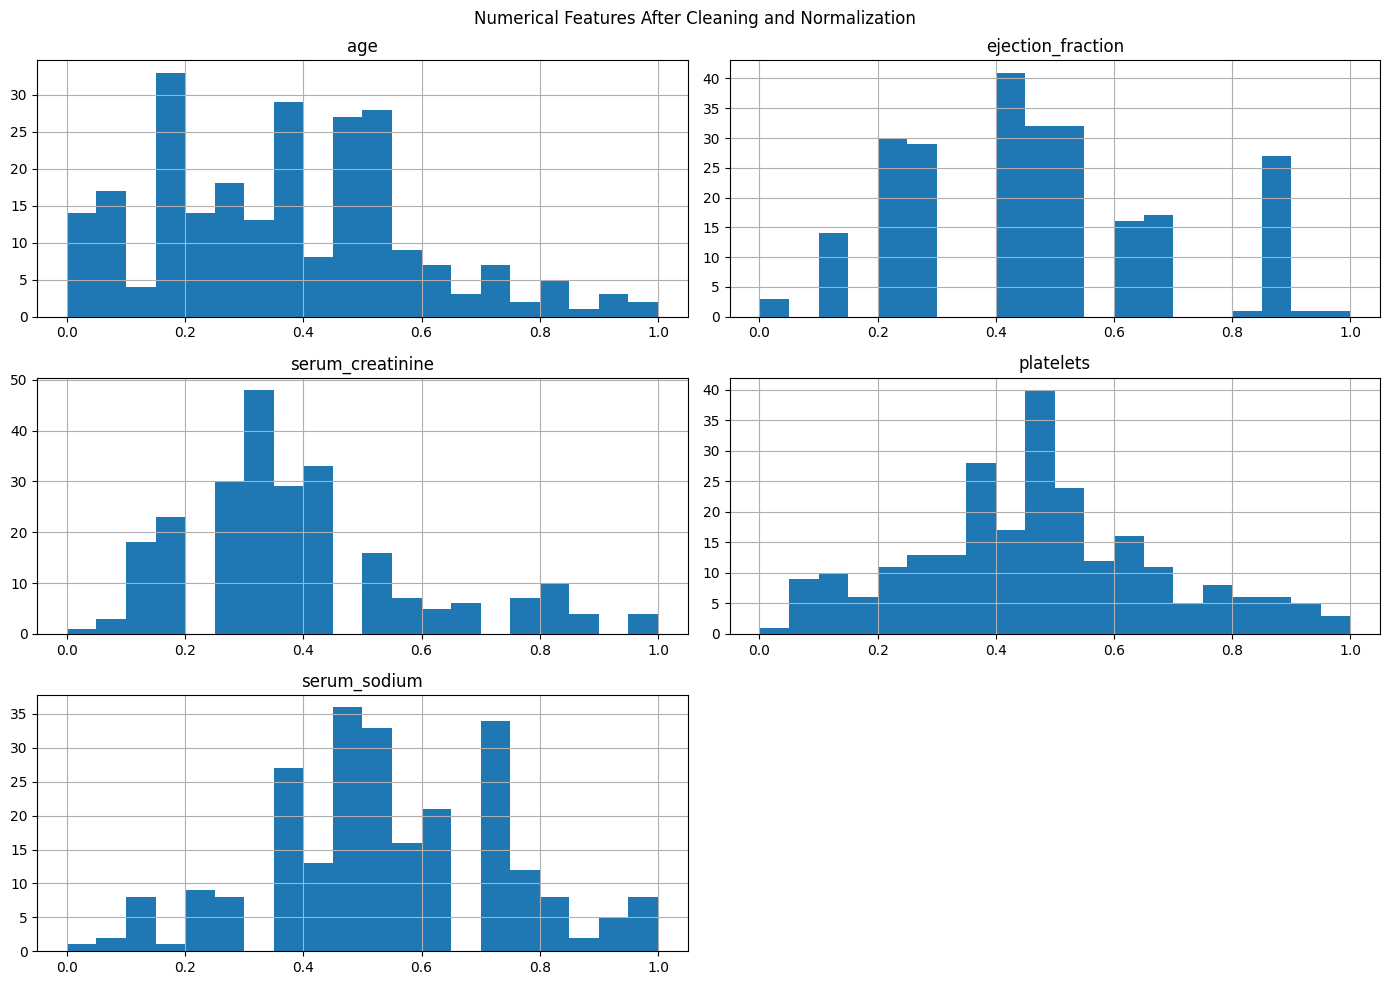

In [24]:
# Cell 22: Histograms after cleaning

df_encoded[numerical_columns].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Numerical Features After Cleaning and Normalization")
plt.tight_layout()
plt.show()

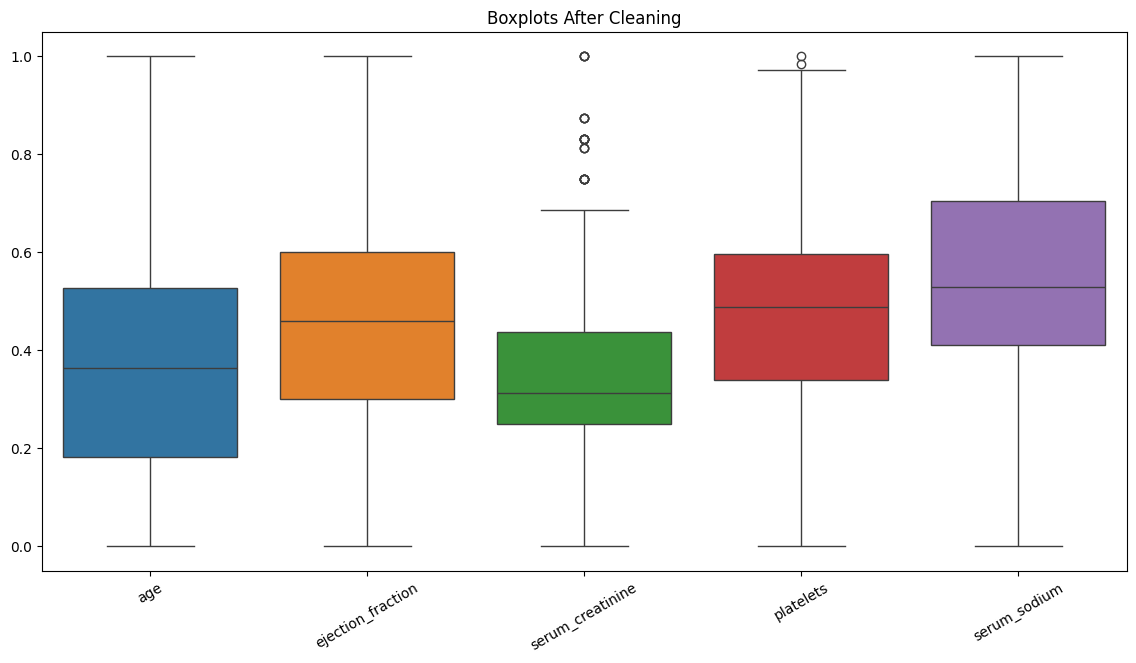

In [25]:
# Cell 23: Boxplots after cleaning

plt.figure(figsize=(14, 7))

sns.boxplot(data=df_encoded[numerical_columns])

plt.title("Boxplots After Cleaning")
plt.xticks(rotation=30)
plt.show()

In [26]:
# Cell 24: Final missing value check

missing_values = df_encoded.isnull().sum()

print("Missing values in final dataset:")
print(missing_values)

if missing_values.sum() == 0:
    print("\n✓ No missing values remain.")
else:
    print("\n⚠ Missing values still exist.")

Missing values in final dataset:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
time                        0
DEATH_EVENT                 0
risk_score                  0
sex_1                       0
smoking_1                   0
age_group_>60               0
dtype: int64

✓ No missing values remain.


In [27]:
# Cell 25: Final cleaned dataset

print("Final dataset shape:", df_encoded.shape)

df_encoded.head()

Final dataset shape: (244, 15)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT,risk_score,sex_1,smoking_1,age_group_>60
0,0.636364,0,582,0,0.10,1,0.496894,0.875,0.117647,4,1,0.0875,True,False,True
1,0.272727,0,7861,0,0.46,0,0.491795,0.375,0.470588,6,1,0.1725,True,False,False
2,0.454545,0,146,0,0.10,0,0.177019,0.500,0.058824,7,1,0.0500,True,True,True
3,0.181818,1,111,0,0.10,0,0.326087,0.875,0.529412,7,1,0.0875,True,False,False
5,0.909091,1,47,0,0.50,1,0.307453,1.000,0.235294,8,1,0.5000,True,True,True


In [28]:
# Cell 26: Save cleaned dataset

df_encoded.to_csv(
    "heart_failure_cleaned.csv",
    index=False
)

print("Cleaned dataset saved as heart_failure_cleaned.csv")


Cleaned dataset saved as heart_failure_cleaned.csv
